# Week 2 — Supervised Machine Learning Models

**Yuva Internship · Week 2**

Week 1 produced a clean, model-ready dataset. This notebook uses it to build, train and
compare supervised models with scikit-learn, covering both **regression** and
**classification**.

### What you will be able to do by the end

| Part | Skill |
|---|---|
| 1 | Split data honestly: train, test, and stratified splits |
| 2 | Fit and interpret **Linear Regression** |
| 3 | Fit and interpret **Logistic Regression** |
| 4 | Fit **Decision Trees** and see overfitting happen |
| 5 | Fit a **Random Forest** and read feature importance |
| 6 | Fit **K-Nearest Neighbors** and understand why scaling matters |
| 7 | Evaluate with accuracy, precision, recall, F1, ROC-AUC, R², MAE, RMSE |
| 8 | Use cross-validation instead of peeking at the test set |
| 9 | Choose a decision threshold from the cost of errors |

> **The dataset is synthetic teaching data.** Every score here describes the generator,
> not a real business.

### The one rule that matters most

> **Fit every transformation on the training data only.**

If the scaler or imputer sees the test rows while learning its parameters, information
leaks from test to train and the reported score is optimistically wrong. The effect is
small enough to pass unnoticed, which is exactly why it is dangerous. This notebook wraps
preprocessing in a `Pipeline` so the rule enforces itself.

---
## 0 · Setup

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline
warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

DATA_PATH = Path("..", "data", "customer_churn_raw.csv")
print("Python   :", sys.version.split()[0])
print("NumPy    :", np.__version__)
print("Pandas   :", pd.__version__)
import sklearn
print("sklearn  :", sklearn.__version__)

Python   : 3.11.2
NumPy    : 2.4.6
Pandas   : 3.0.6


sklearn  : 1.9.1


---
## 1 · The dataset and the two tasks

The same table supports two different supervised problems:

* **Classification** — predict `churn` (`Yes` / `No`). The target is a *category*.
* **Regression** — predict `monthly_charges`. The target is a *number*.

Using Linear Regression on churn would be a category error: the model would output
numbers such as 0.37 for "churn", which are not probabilities and not labels. Choosing the
right task type is the first decision in supervised learning.

In [2]:
df = pd.read_csv(DATA_PATH)
print("shape:", df.shape)
df.head()

shape: (1800, 13)


,customer_id,tenure_months,monthly_charges,total_charges,support_tickets,senior_citizen,contract,internet_service,payment_method,paperless_billing,partner,dependents,churn
0,C000001,36.000,55.510,"2,017.090",3.000,0,Month-to-month,DSL,NaN,Yes,No,No,No
1,C000002,53.000,83.210,"4,590.070",2.000,0,One year,Fiber optic,Electronic check,No,No,No,No
2,C000003,28.000,29.070,786.730,1.000,1,Month-to-month,No,Credit card,Yes,Yes,No,No
3,C000004,70.000,31.150,"2,130.910",NaN,1,Month-to-month,No,Bank transfer,Yes,No,No,No
4,C000005,47.000,76.450,"3,641.100",2.000,0,Month-to-month,Fiber optic,Credit card,No,No,No,Yes


In [3]:
NUMERIC_FEATURES = ["tenure_months", "monthly_charges", "total_charges",
                    "support_tickets", "senior_citizen"]
CATEGORICAL_FEATURES = ["contract", "internet_service", "payment_method",
                        "paperless_billing", "partner", "dependents"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

print("churn counts:")
print(df["churn"].value_counts().to_string())
print()
print(f"Positive rate: {(df['churn'] == 'Yes').mean():.3%}")

churn counts:
churn
No     1320
Yes     480

Positive rate: 26.667%


### Class imbalance is the central fact of this exercise

26.7% of customers churn. That single number determines which metrics are meaningful.

A model that **never predicts churn** is right 73.3% of the time while being completely
useless. Any accuracy figure must be read against that baseline, not against zero.

---
## 2 · Splitting: the test set is a promise

We hold out 20% of the rows and **do not look at them** until the very end. Everything
that involves a decision — scaling, encoding, picking a model, choosing a hyperparameter —
happens on the training portion only.

`stratify=y` keeps the churn rate identical in both halves. Without it, a random split
could give the test set a noticeably different balance and make the score depend on luck.

In [4]:
from sklearn.model_selection import train_test_split

X = df[FEATURES]
y = df["churn"].map({"No": 0, "Yes": 1}).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {len(X_train):,} rows  |  churn rate {y_train.mean():.3f}")
print(f"Test : {len(X_test):,} rows  |  churn rate {y_test.mean():.3f}")

Train: 1,440 rows  |  churn rate 0.267
Test : 360 rows  |  churn rate 0.267


---
## 3 · Why every model gets the same pipeline

Two transformations were established in Week 1:

* numeric columns → median imputation, then standardisation;
* categorical columns → most-frequent imputation, then one-hot encoding.

Wrapping them in a `ColumnTransformer` inside a `Pipeline` has three effects:

1. **No leakage.** `fit` learns medians, categories and scaling parameters from `X_train`.
2. **Consistency.** The identical transformation is applied to test data and to future data.
3. **Comparability.** Every model sees the same inputs, so a difference in score reflects
   the algorithm, not the preparation.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def build_preprocessor(numeric=NUMERIC_FEATURES, categorical=CATEGORICAL_FEATURES, scale=True):
    """Impute, encode and optionally scale; fitted on training data only."""
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scaler", StandardScaler()))

    return ColumnTransformer(
        transformers=[
            ("numeric", Pipeline(numeric_steps), numeric),
            ("categorical", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]), categorical),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


def make_pipeline(estimator, scale=True):
    return Pipeline([
        ("preprocessor", build_preprocessor(scale=scale)),
        ("model", estimator),
    ])


demo = make_pipeline(__import__("sklearn.linear_model", fromlist=["LogisticRegression"]).LogisticRegression(max_iter=1000))
demo.fit(X_train, y_train)
print("Pipeline fitted. Steps:", list(demo.named_steps))
print("Transformed feature count:", demo.named_steps["preprocessor"].transform(X_train[:5]).shape[1])

Pipeline fitted. Steps: ['preprocessor', 'model']
Transformed feature count: 21


---
## 4 · A reusable evaluation function

Different metrics answer different questions. Collecting them in one function avoids the
common mistake of reporting whichever number looks best.

| Metric | Question it answers | Misleading when |
|---|---|---|
| **Accuracy** | What fraction were classified correctly? | Classes are imbalanced |
| **Balanced accuracy** | Average of per-class recall | You need a single headline number |
| **Precision** | Of those flagged, how many were right? | You actually care about finding all positives |
| **Recall** | Of the real positives, how many were found? | False alarms are very costly |
| **F1** | Harmonic mean of precision and recall | The two costs are asymmetric |
| **ROC-AUC** | How well does the model *rank*? | Precision at the top matters more than ranking |
| **PR-AUC** | Ranking quality for the minority class | — (usually the honest choice when imbalanced) |

**ROC-AUC and PR-AUC do not depend on a threshold.** They measure ranking quality. Every
other metric above depends on where you place the cut-off.

In [6]:
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             brier_score_loss, confusion_matrix, f1_score, log_loss,
                             matthews_corrcoef, precision_score, recall_score, roc_auc_score)


def evaluate_classifier(name, pipeline, X_test, y_test):
    """Score one fitted classifier and return a dictionary of metrics."""
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

    return {
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "balanced_acc": balanced_accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, y_prob),
        "pr_auc": average_precision_score(y_test, y_prob),
        "mcc": matthews_corrcoef(y_test, y_pred),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }

---
## 5 · Baseline first

Before any real model, fit a **dummy classifier**. It ignores the features entirely.
`most_frequent` always predicts the majority class; `stratified` guesses at random,
respecting the class frequencies.

A real model that cannot beat these has learned nothing. Establishing the baseline first
also stops you from being impressed by a number that is actually worse than doing nothing.

In [7]:
from sklearn.dummy import DummyClassifier

baseline_rows = []
for strategy in ["most_frequent", "stratified"]:
    pipe = make_pipeline(DummyClassifier(strategy=strategy, random_state=RANDOM_STATE))
    pipe.fit(X_train, y_train)
    baseline_rows.append(evaluate_classifier(f"Dummy ({strategy})", pipe, X_test, y_test))

pd.DataFrame(baseline_rows)[["model", "accuracy", "balanced_acc", "precision", "recall", "f1", "roc_auc"]]

,model,accuracy,balanced_acc,precision,recall,f1,roc_auc
0,Dummy (most_frequent),0.733,0.500,0.000,0.000,0.000,0.500
1,Dummy (stratified),0.661,0.554,0.352,0.323,0.337,0.554


> The `most_frequent` baseline scores **0.733** accuracy and **0.000** recall.
> That pair of numbers is the whole lesson of imbalanced classification: high accuracy,
> zero usefulness. Keep 0.733 in mind for everything that follows.

---
## 6 · Regression: Linear Regression

Linear Regression fits `y = w₀ + w₁x₁ + … + wₙxₙ` by minimising squared error. It is the
natural starting point for a numeric target.

### A leakage trap worth knowing

`total_charges` is approximately `monthly_charges × tenure`. If we try to predict
`monthly_charges` while including `total_charges` as an input, the model can (almost)
recover the answer from the input. It would score beautifully and be useless in
production, where you want to *estimate* a charge you do not yet know.

So we drop it.

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

REGRESSION_TARGET = "monthly_charges"
REGRESSION_NUMERIC = ["tenure_months", "support_tickets", "senior_citizen"]
REGRESSION_FEATURES = REGRESSION_NUMERIC + CATEGORICAL_FEATURES

reg_data = df.loc[df[REGRESSION_TARGET].notna()].copy()
Xr = reg_data[REGRESSION_FEATURES]
yr = reg_data[REGRESSION_TARGET].astype(float)

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, yr, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Usable rows: {len(reg_data):,}  (dropped {df[REGRESSION_TARGET].isna().sum()} with no target)")
print(f"Excluded from inputs: total_charges (derived from the target)")
print(f"Train {len(Xr_train):,} / Test {len(Xr_test):,}")

Usable rows: 1,722  (dropped 78 with no target)
Excluded from inputs: total_charges (derived from the target)
Train 1,377 / Test 345


In [9]:
def evaluate_regressor(name, pipeline, X_test, y_test):
    y_pred = pipeline.predict(X_test)
    return {
        "model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred),
    }


linear_pipe = Pipeline([
    ("preprocessor", build_preprocessor(REGRESSION_NUMERIC, CATEGORICAL_FEATURES)),
    ("model", LinearRegression()),
])
linear_pipe.fit(Xr_train, yr_train)

linear_scores = evaluate_regressor("Linear Regression", linear_pipe, Xr_test, yr_test)
pd.DataFrame([linear_scores])

,model,MAE,RMSE,R2
0,Linear Regression,7.589,9.650,0.818


### Reading those three numbers

* **MAE = 7.59** — the average prediction is off by about 7.59 currency units.
* **RMSE = 9.65** — larger than MAE because squaring punishes big misses harder. The gap
  between MAE and RMSE tells you there are some large errors.
* **R² = 0.818** — the model explains 81.8% of the variance in monthly charges.

R² is relative to a "predict the mean" baseline, so 0.818 is genuinely good. But note what
MAE tells us in absolute terms: an error of 7.59 on a bill averaging 60.73 is about 12% —
useful for triage, not for billing a customer.

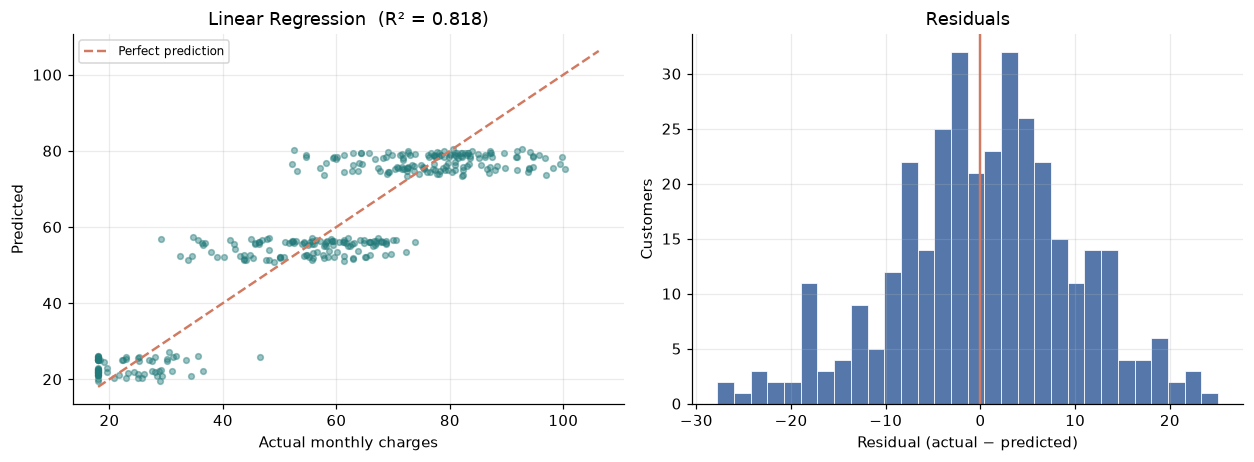

Mean residual : +0.36   (near zero = no systematic bias)
Residual std  : 9.64


In [10]:
y_pred_linear = linear_pipe.predict(Xr_test)
residual = yr_test.to_numpy() - y_pred_linear

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))

axes[0].scatter(yr_test, y_pred_linear, s=14, alpha=0.45, color="#237A7A")
lims = [yr.min(), yr.max()]
axes[0].plot(lims, lims, "--", color="#D17A61", linewidth=1.6, label="Perfect prediction")
axes[0].set_xlabel("Actual monthly charges")
axes[0].set_ylabel("Predicted")
axes[0].set_title(f"Linear Regression  (R² = {linear_scores['R2']:.3f})")
axes[0].legend(fontsize=8)

axes[1].hist(residual, bins=30, color="#5577AA", edgecolor="white", linewidth=0.5)
axes[1].axvline(0, color="#D17A61", linewidth=1.6)
axes[1].set_xlabel("Residual (actual − predicted)")
axes[1].set_ylabel("Customers")
axes[1].set_title("Residuals")

plt.tight_layout()
plt.show()

print(f"Mean residual : {residual.mean():+.2f}   (near zero = no systematic bias)")
print(f"Residual std  : {residual.std():.2f}")

### Why the predictions form horizontal bands

The scatter looks like stripes. That is not a bug — it is a property of the data.

Monthly charges in this dataset are driven almost entirely by **categorical** variables:
contract type, internet service, payment method. Customers who share those categories
receive nearly identical predictions, producing a band per combination.

The lesson: when a regression target is a step function of categorical inputs, no amount
of model complexity can produce a smooth diagonal. The ceiling is a property of the
features, not of the algorithm.

---
## 7 · Classification: Logistic Regression

Logistic Regression applies the sigmoid function to a linear combination of inputs:

$$P(y=1) = \frac{1}{1 + e^{-(w_0 + w_1x_1 + \dots)}}$$

The output is a **probability between 0 and 1**, converted to a label by a threshold —
0.5 by default. Despite the name, it is a classification algorithm.

`class_weight="balanced"` tells the optimiser that the minority class matters as much as
the majority one. Without it, the model happily predicts "No" for almost everyone because
that minimises the loss.

In [11]:
from sklearn.linear_model import LogisticRegression

logit = make_pipeline(
    LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)
)
logit.fit(X_train, y_train)

logit_scores = evaluate_classifier("Logistic Regression", logit, X_test, y_test)
pd.DataFrame([logit_scores])[["model", "accuracy", "balanced_acc", "precision", "recall", "f1", "roc_auc", "pr_auc"]]

,model,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,0.678,0.671,0.432,0.656,0.521,0.769,0.518


### Coefficients: what the model learned

For a linear model the coefficients are interpretable — with one large caveat. The
one-hot columns are collinear (they sum to 1 within each feature), so **individual
one-hot coefficients must not be read as independent effects**. Only the numeric
features, which are standardised, have clean per-unit interpretations.

In [12]:
coefs = logit.named_steps["model"].coef_[0]
names = logit.named_steps["preprocessor"].get_feature_names_out()

coef_table = (pd.DataFrame({"feature": names, "coefficient": coefs})
              .assign(abs_coef=lambda d: d["coefficient"].abs())
              .sort_values("abs_coef", ascending=False)
              .drop(columns="abs_coef"))

print("Largest-magnitude coefficients (positive pushes towards churn):")
coef_table.head(12).reset_index(drop=True)

Largest-magnitude coefficients (positive pushes towards churn):


,feature,coefficient
0,contract_Two year,-1.229
1,contract_Month-to-month,1.017
2,monthly_charges,0.722
3,tenure_months,-0.398
4,support_tickets,0.338
5,internet_service_DSL,-0.317
6,internet_service_Fiber optic,0.284
7,partner_Yes,-0.271
8,paperless_billing_No,-0.256
9,internet_service_No,-0.240


---
## 8 · Classification: Decision Tree

A decision tree repeatedly splits the data on the feature that best separates the classes.
It is highly interpretable — you can read the splits as rules — but it has one dangerous
property: **unlimited depth means unlimited memorisation**.

`max_depth` and `min_samples_leaf` are the brakes. We will see below exactly what happens
when you release them.

In [13]:
from sklearn.tree import DecisionTreeClassifier

tree = make_pipeline(
    DecisionTreeClassifier(max_depth=5, min_samples_leaf=20,
                           class_weight="balanced", random_state=RANDOM_STATE)
)
tree.fit(X_train, y_train)

tree_scores = evaluate_classifier("Decision Tree", tree, X_test, y_test)
pd.DataFrame([tree_scores])[["model", "accuracy", "balanced_acc", "precision", "recall", "f1", "roc_auc", "pr_auc"]]

,model,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
0,Decision Tree,0.653,0.661,0.409,0.677,0.510,0.725,0.486


### Watching overfitting happen

Train the same tree at every depth from 1 to 18 and plot both the training score and the
test score.

The training score climbs towards 1.0 — a deep tree can memorise every row. The test score
stops improving and then *declines*. The widening gap between the two lines is **variance**,
and it is the reason hyperparameters are chosen on validation data.

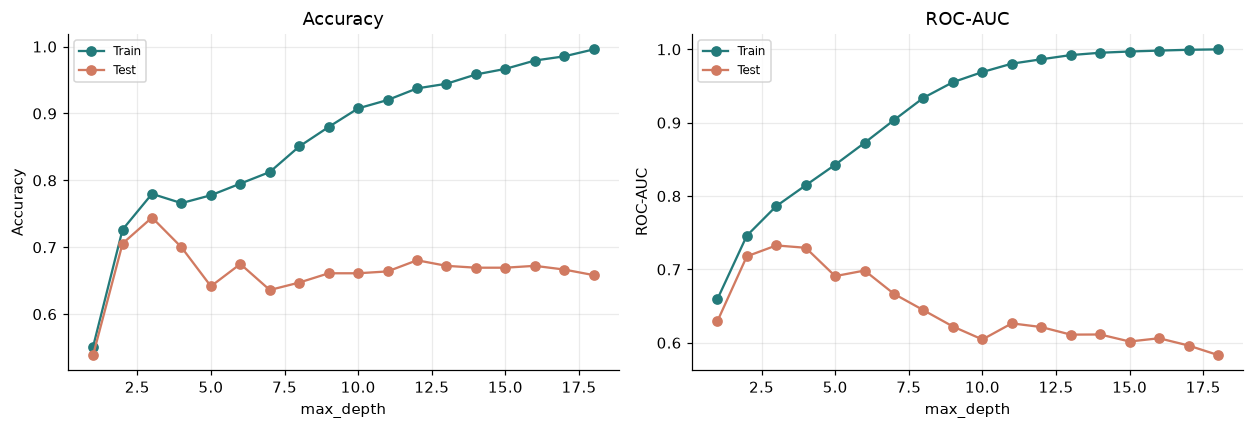

Best test ROC-AUC at depth 3. Deeper trees keep improving on TRAIN only.


In [14]:
depths = list(range(1, 19))
rows = []
for depth in depths:
    pipe = make_pipeline(
        DecisionTreeClassifier(max_depth=depth, class_weight="balanced", random_state=RANDOM_STATE)
    )
    pipe.fit(X_train, y_train)
    rows.append({
        "depth": depth,
        "train_acc": accuracy_score(y_train, pipe.predict(X_train)),
        "test_acc": accuracy_score(y_test, pipe.predict(X_test)),
        "train_auc": roc_auc_score(y_train, pipe.predict_proba(X_train)[:, 1]),
        "test_auc": roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1]),
    })

depth_curve = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))
for ax, metric, title in [(axes[0], "acc", "Accuracy"), (axes[1], "auc", "ROC-AUC")]:
    ax.plot(depth_curve["depth"], depth_curve[f"train_{metric}"], "o-", color="#237A7A", label="Train")
    ax.plot(depth_curve["depth"], depth_curve[f"test_{metric}"], "o-", color="#D17A61", label="Test")
    ax.set_xlabel("max_depth")
    ax.set_ylabel(title)
    ax.set_title(title)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

best_depth = int(depth_curve.loc[depth_curve["test_auc"].idxmax(), "depth"])
print(f"Best test ROC-AUC at depth {best_depth}. Deeper trees keep improving on TRAIN only.")

---
## 9 · Classification: Random Forest

A Random Forest trains many decision trees, each on a **bootstrap sample** of the rows and
a **random subset of features** at each split, then averages their votes.

Averaging many decorrelated trees cancels much of the variance that ruins a single deep
tree. It is usually one of the strongest off-the-shelf methods on tabular data, and it
needs little tuning.

The cost is interpretability: there is no single tree to read. We inspect **feature
importance** instead.

In [15]:
from sklearn.ensemble import RandomForestClassifier

forest = make_pipeline(
    RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                           class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1)
)
forest.fit(X_train, y_train)

forest_scores = evaluate_classifier("Random Forest", forest, X_test, y_test)
pd.DataFrame([forest_scores])[["model", "accuracy", "balanced_acc", "precision", "recall", "f1", "roc_auc", "pr_auc"]]

,model,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
0,Random Forest,0.717,0.694,0.477,0.646,0.549,0.760,0.511


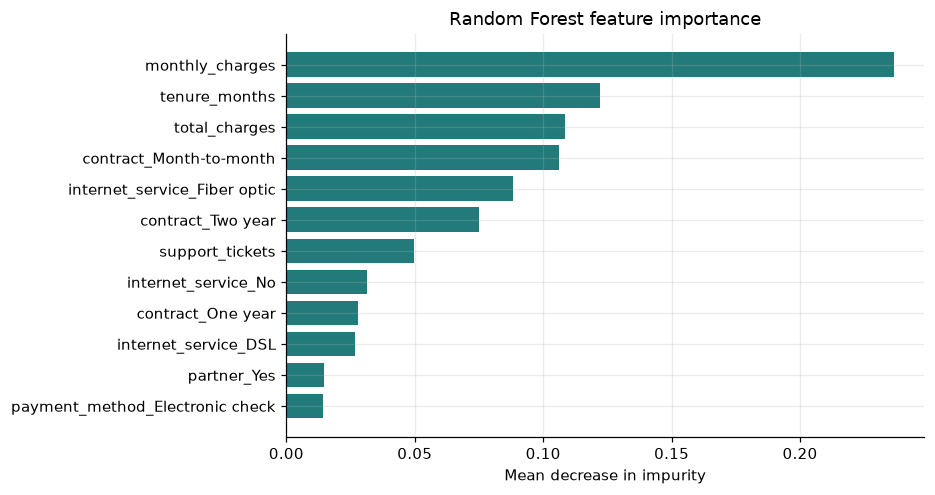

Impurity importance favours high-cardinality continuous features.
It ranks usefulness inside THIS model — it is not a causal effect.


In [16]:
importance = (pd.DataFrame({
    "feature": forest.named_steps["preprocessor"].get_feature_names_out(),
    "importance": forest.named_steps["model"].feature_importances_,
}).sort_values("importance", ascending=False).head(12))

fig, ax = plt.subplots(figsize=(8.6, 4.6))
ax.barh(importance["feature"][::-1], importance["importance"][::-1], color="#237A7A")
ax.set_xlabel("Mean decrease in impurity")
ax.set_title("Random Forest feature importance")
plt.tight_layout()
plt.show()

print("Impurity importance favours high-cardinality continuous features.")
print("It ranks usefulness inside THIS model — it is not a causal effect.")

---
## 10 · Classification: K-Nearest Neighbors

KNN makes no model at all. To classify a new point it finds the *k* closest training
points and takes a vote.

Two consequences follow immediately:

1. **It needs scaling.** "Distance" is meaningless if `total_charges` (thousands) and
   `senior_citizen` (0 or 1) are compared in raw units. The large-magnitude feature
   dominates every distance, so KNN would effectively ignore the others.
2. **Prediction is slow.** There is no fitted model to query — every prediction scans the
   training set.

`weights="distance"` gives nearer neighbours more influence than distant ones.

In [17]:
from sklearn.neighbors import KNeighborsClassifier

knn = make_pipeline(KNeighborsClassifier(n_neighbors=15, weights="distance"))
knn.fit(X_train, y_train)

knn_scores = evaluate_classifier("K-Nearest Neighbors", knn, X_test, y_test)
pd.DataFrame([knn_scores])[["model", "accuracy", "balanced_acc", "precision", "recall", "f1", "roc_auc", "pr_auc"]]

,model,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
0,K-Nearest Neighbors,0.744,0.634,0.528,0.396,0.452,0.734,0.468


### Why scaling matters to KNN — measured

Fit the identical KNN **without** the scaler and compare. Same algorithm, same `k`, same
data — only the preparation differs.

In [18]:
knn_unscaled = make_pipeline(KNeighborsClassifier(n_neighbors=15, weights="distance"), scale=False)
knn_unscaled.fit(X_train, y_train)
unscaled_scores = evaluate_classifier("KNN (unscaled)", knn_unscaled, X_test, y_test)

comparison = pd.DataFrame([
    {"setting": "With StandardScaler", "accuracy": knn_scores["accuracy"],
     "recall": knn_scores["recall"], "roc_auc": knn_scores["roc_auc"]},
    {"setting": "Without scaling", "accuracy": unscaled_scores["accuracy"],
     "recall": unscaled_scores["recall"], "roc_auc": unscaled_scores["roc_auc"]},
])
comparison

,setting,accuracy,recall,roc_auc
0,With StandardScaler,0.744,0.396,0.734
1,Without scaling,0.708,0.156,0.608


> This is why preprocessing is not a detail. The same algorithm degrades measurably when
> features are left on incompatible scales, and nothing in the training output would warn
> you.

---
## 11 · Comparing all four models

Now put them side by side on the untouched test set.

In [19]:
results = pd.DataFrame([logit_scores, forest_scores, tree_scores, knn_scores])
results = results.sort_values("roc_auc", ascending=False).reset_index(drop=True)
results[["model", "accuracy", "balanced_acc", "precision", "recall", "f1", "roc_auc", "pr_auc"]]

,model,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,0.678,0.671,0.432,0.656,0.521,0.769,0.518
1,Random Forest,0.717,0.694,0.477,0.646,0.549,0.760,0.511
2,K-Nearest Neighbors,0.744,0.634,0.528,0.396,0.452,0.734,0.468
3,Decision Tree,0.653,0.661,0.409,0.677,0.510,0.725,0.486


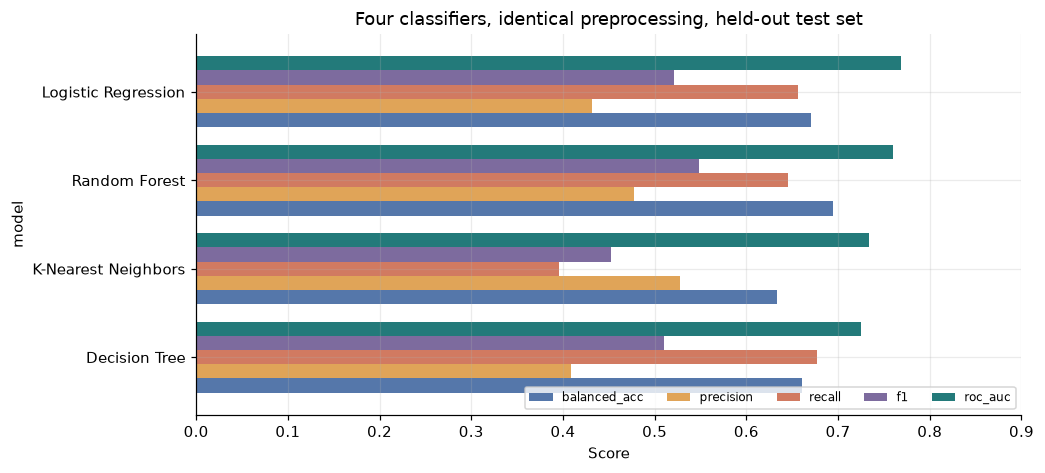

In [20]:
metrics_to_plot = ["balanced_acc", "precision", "recall", "f1", "roc_auc"]
plot_data = results.set_index("model")[metrics_to_plot].sort_values("roc_auc")

fig, ax = plt.subplots(figsize=(9.6, 4.4))
plot_data.plot(kind="barh", ax=ax, width=0.8,
               color=["#5577AA", "#E0A458", "#D17A61", "#7D6B9E", "#237A7A"])
ax.set_xlabel("Score")
ax.set_title("Four classifiers, identical preprocessing, held-out test set")
ax.set_xlim(0, 0.9)
ax.legend(ncols=5, fontsize=7.6, loc="lower right")
plt.tight_layout()
plt.show()

### The disagreement is the finding

Look carefully:

* **KNN has the highest accuracy** (0.744) but the **lowest recall** (0.396) — it misses
  roughly 6 in 10 churners.
* **Logistic Regression has the best ROC-AUC** (0.769) and roughly double KNN's recall.
* **Logistic Regression's accuracy (0.678) is below the 0.733 do-nothing baseline.**

That last point is not a failure. Because `class_weight="balanced"` deliberately trades
accuracy for recall, the model *chooses* to make more positive predictions. It is worse by
the accuracy metric and better at the job. Reporting only accuracy would have hidden this
completely.

**There is no single winner.** The right choice depends on the cost of a false negative
versus a false positive.

---
## 12 · Confusion matrices: the costs made visible

A confusion matrix breaks the errors into their two distinct kinds:

* **False positive (FP)** — predicted churn, customer stayed. Cost: a wasted retention offer.
* **False negative (FN)** — predicted loyal, customer left. Cost: the customer's entire
  future value.

These are not equally expensive, and the matrix is where that asymmetry becomes concrete.

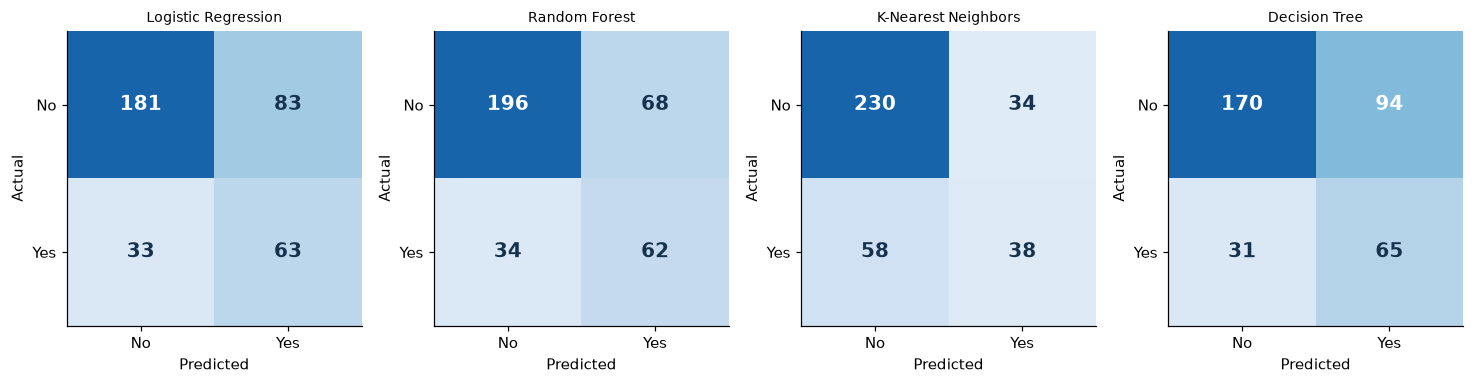

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.7))
for ax, (name, pipe) in zip(axes, [
    ("Logistic Regression", logit), ("Random Forest", forest),
    ("K-Nearest Neighbors", knn), ("Decision Tree", tree),
]):
    cm = confusion_matrix(y_test, pipe.predict(X_test), labels=[0, 1])
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() * 1.25)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=13,
                    fontweight="bold", color="white" if cm[i, j] > cm.max() * 0.55 else "#17324D")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["No", "Yes"]); ax.set_yticklabels(["No", "Yes"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title(name, fontsize=9)
    ax.grid(False)
plt.tight_layout()
plt.show()

---
## 13 · Cross-validation: choosing without touching the test set

Every score so far came from the test set. If we now pick the "best" model using those
numbers, the test set has quietly become a validation set — and our final estimate is
optimistic.

**Cross-validation** solves this. Split the *training* data into 5 folds; train on 4,
validate on the 1 held out; rotate. Average the scores. The test set stays untouched
until the very end.

In [22]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

candidates = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=15, weights="distance"),
}

cv_rows = []
for name, estimator in candidates.items():
    pipe = make_pipeline(estimator)
    auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1")
    cv_rows.append({
        "model": name,
        "cv_auc_mean": auc.mean(), "cv_auc_std": auc.std(),
        "cv_f1_mean": f1.mean(), "cv_f1_std": f1.std(),
    })

cv_results = pd.DataFrame(cv_rows).sort_values("cv_auc_mean", ascending=False)
cv_results

,model,cv_auc_mean,cv_auc_std,cv_f1_mean,cv_f1_std
0,Logistic Regression,0.805,0.025,0.599,0.022
2,Random Forest,0.796,0.026,0.590,0.032
1,Decision Tree,0.767,0.027,0.559,0.012
3,K-Nearest Neighbors,0.766,0.030,0.451,0.052


> The pipelines inside `cross_val_score` are refitted from scratch on each fold, so the
> imputer, encoder and scaler relearn their parameters five times. That is the correct
> behaviour and the reason wrapping preprocessing in a `Pipeline` is not optional.

Note the standard deviations: roughly 0.025. The top two models differ by about 0.01 in
mean ROC-AUC — **less than half a standard deviation**. They are not meaningfully
different on 1,440 training rows. Reporting one as "the best" would be over-claiming.

---
## 14 · Choosing a threshold

The default 0.5 cut-off is a convention, not an optimum. The model outputs a probability;
you decide where to draw the line.

Lowering the threshold catches more churners (higher recall) at the price of more false
alarms (lower precision). Raising it does the opposite.

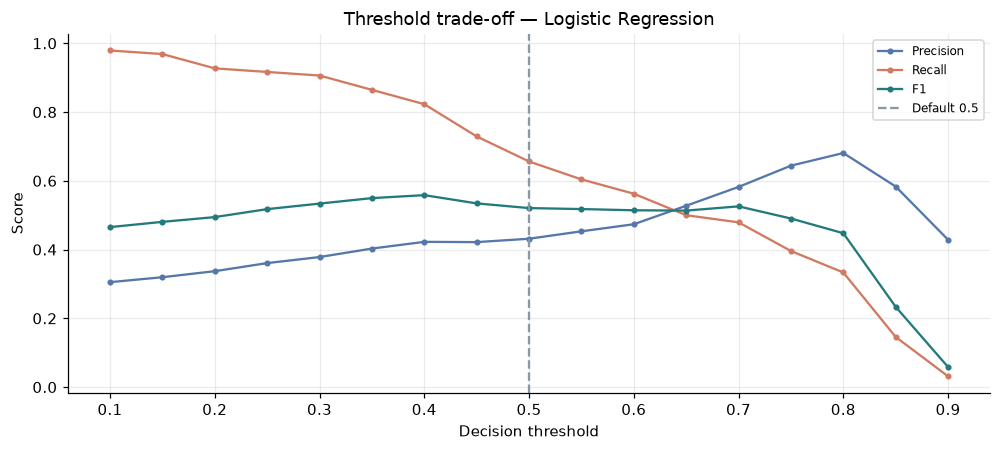

Threshold maximising F1: 0.40
   threshold  precision  recall    f1  accuracy  flagged_rate
6      0.400      0.422   0.823 0.558     0.653         0.519


In [23]:
y_prob_logit = logit.predict_proba(X_test)[:, 1]

threshold_rows = []
for threshold in np.arange(0.10, 0.91, 0.05):
    pred = (y_prob_logit >= threshold).astype(int)
    threshold_rows.append({
        "threshold": round(threshold, 2),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "accuracy": accuracy_score(y_test, pred),
        "flagged_rate": pred.mean(),
    })

threshold_df = pd.DataFrame(threshold_rows)

fig, ax = plt.subplots(figsize=(9.2, 4.2))
ax.plot(threshold_df["threshold"], threshold_df["precision"], "o-", markersize=3, color="#5577AA", label="Precision")
ax.plot(threshold_df["threshold"], threshold_df["recall"], "o-", markersize=3, color="#D17A61", label="Recall")
ax.plot(threshold_df["threshold"], threshold_df["f1"], "o-", markersize=3, color="#237A7A", label="F1")
ax.axvline(0.5, ls="--", color="#8A97A5", label="Default 0.5")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_title("Threshold trade-off — Logistic Regression")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

best_threshold = float(threshold_df.loc[threshold_df["f1"].idxmax(), "threshold"])
print(f"Threshold maximising F1: {best_threshold:.2f}")
print(threshold_df.iloc[[int(threshold_df['f1'].idxmax())]])

> A threshold is a **business decision**, not a modelling one. If a missed churner costs
> ten times a wasted offer, you should accept many more false positives and move the
> threshold left. The data cannot answer that question; only the cost structure can.

---
## 15 · Class weighting: the same trade-off, chosen at training time

The threshold moves the cut-off *after* training. `class_weight` changes what the model
optimises *during* training. Both are legitimate; they are different levers.

In [24]:
weight_rows = []
for label, weight in [("No weighting", None), ("balanced", "balanced")]:
    pipe = make_pipeline(LogisticRegression(max_iter=2000, class_weight=weight, random_state=RANDOM_STATE))
    pipe.fit(X_train, y_train)
    score = evaluate_classifier(label, pipe, X_test, y_test)
    weight_rows.append({
        "setting": label,
        "accuracy": score["accuracy"], "precision": score["precision"],
        "recall": score["recall"], "f1": score["f1"],
        "flagged_rate": float(pipe.predict(X_test).mean()),
    })

pd.DataFrame(weight_rows)

,setting,accuracy,precision,recall,f1,flagged_rate
0,No weighting,0.775,0.606,0.448,0.515,0.197
1,balanced,0.678,0.432,0.656,0.521,0.406


> Unweighted, the model flags 19.7% of customers and catches 44.8% of churners.
> Balanced, it flags 40.6% and catches 65.6% — nearly 15 percentage points more churners,
> at the cost of precision.
>
> Note that **accuracy fell while quality rose.** That sentence is the entire reason this
> week uses more than one metric.

---
## 16 · Summary

| Task | Models compared | Best on the held-out set |
|---|---|---|
| Classification (churn) | Logistic Regression, Decision Tree, Random Forest, KNN, + 2 baselines | Logistic Regression by ROC-AUC (0.769); KNN by accuracy (0.744) |
| Regression (monthly charges) | Linear Regression | R² 0.818, MAE 7.59 |

### What actually matters

1. **Establish a baseline first.** A dummy model scoring 0.733 accuracy redefines what
   "good" means.
2. **Accuracy alone is dangerous** on imbalanced data. Here the best-accuracy model is
   near the worst-recall model.
3. **Precision and recall trade off.** Choose between them from costs, not from taste.
4. **Threshold and class weight are separate levers** for the same trade-off.
5. **Cross-validate before you claim a winner.** A 0.01 difference in ROC-AUC is noise.
6. **Scale matters** for distance-based methods — measured, not assumed.
7. **Fit preprocessing on training data only**, every time, including inside CV folds.

### Honest limits of these numbers

* The dataset is **synthetic**. These scores describe a generator, not customers.
* 360 test rows means roughly ±2.5 percentage points of sampling noise on accuracy.
* Hyperparameters were fixed in advance, not tuned. Week 3 does the tuning properly.
* `total_charges` was excluded from regression to avoid leakage — a good decision that
  also caps the achievable R².